<a href="https://colab.research.google.com/github/vivi-dot-exe/RUL-Predictor/blob/main/Remaining_Useful_Life_(RUL)_Predictor.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Phase 1: Getting and Loading the Data for your NASA Turbofan Engine dataset.

## Download the dataset
Use the NASA Turbofan Engine Degradation Simulation Dataset

What it contains: Simulated sensor readings from aircraft engines over time, tracking them from normal operation until they eventually fail.

Why it's great: It has multiple features (x variables like 21 different sensor channels) and a clear target (y variable: predicting remaining cycles before failure).

In [46]:
!pip install kagglehub

In [47]:
import kagglehub

### load data

In [48]:
path = kagglehub.dataset_download("behrad3d/nasa-cmaps")
print("Data downloaded to path:", path)

Using Colab cache for faster access to the 'nasa-cmaps' dataset.
Data downloaded to path: /kaggle/input/nasa-cmaps


## Load the Raw Training Data into Pandas

### File directory

In [49]:
import os
for root, dirs, files in os.walk(path):
  if 'train_FD001.txt' in files:
    file_path = os.path.join(root, 'train_FD001.txt')
    print('Found it at:', file_path)

Found it at: /kaggle/input/nasa-cmaps/CMaps/train_FD001.txt


### Data preparation

In [50]:
import pandas as pd
col_names = ['unit', 'cycle', 'setting_1', 'setting_2', 'setting_3']+[f'sensor_{i}' for i in range(1, 22)]

In [51]:
train_df = pd.read_csv(file_path, sep=r'\s+', header=None, names=col_names)
print(train_df.shape)

(20631, 26)


In [52]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20631 entries, 0 to 20630
Data columns (total 26 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   unit       20631 non-null  int64  
 1   cycle      20631 non-null  int64  
 2   setting_1  20631 non-null  float64
 3   setting_2  20631 non-null  float64
 4   setting_3  20631 non-null  float64
 5   sensor_1   20631 non-null  float64
 6   sensor_2   20631 non-null  float64
 7   sensor_3   20631 non-null  float64
 8   sensor_4   20631 non-null  float64
 9   sensor_5   20631 non-null  float64
 10  sensor_6   20631 non-null  float64
 11  sensor_7   20631 non-null  float64
 12  sensor_8   20631 non-null  float64
 13  sensor_9   20631 non-null  float64
 14  sensor_10  20631 non-null  float64
 15  sensor_11  20631 non-null  float64
 16  sensor_12  20631 non-null  float64
 17  sensor_13  20631 non-null  float64
 18  sensor_14  20631 non-null  float64
 19  sensor_15  20631 non-null  float64
 20  sensor

In [53]:
train_df.head()

,unit,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


# Phase 2: Calculating RUL (Remaining Useful Life).

In [54]:
max_cycle = train_df.groupby('unit')['cycle'].max().reset_index()
max_cycle.columns = ['unit', 'max']
max_cycle

,unit,max
0,1,192
1,2,287
2,3,179
3,4,189
4,5,269
...,...,...
95,96,336
96,97,202
97,98,156
98,99,185


In [55]:
train_df = train_df.merge(max_cycle, on='unit', how='left')

train_df['RUL']= train_df['max'] - train_df['cycle']
train_df = train_df.drop(columns=['max'])

print(train_df[['unit', 'cycle', 'RUL']].head(10))

   unit  cycle  RUL
0     1      1  191
1     1      2  190
2     1      3  189
3     1      4  188
4     1      5  187
5     1      6  186
6     1      7  185
7     1      8  184
8     1      9  183
9     1     10  182


# Phase 3: Data Cleaning & Feature Selection

## find dead/flat sensors

In [56]:
sensor_cols = [f'sensor_{i}' for i in range (1, 22)]

## sensors that never fluctuate

In [57]:
constant_sensors = train_df[sensor_cols].std()[train_df[sensor_cols].std() == 0].index.tolist()

## Drop those constant sensors

In [58]:
train_df = train_df.drop(columns=constant_sensors)

## Define final x and y

In [59]:
feature_cols = [col for col in train_df.columns if col not in ['unit', 'cycle', 'RUL']]
X = train_df[feature_cols]
y = train_df['RUL']

In [60]:
print("Final features being used for training:", list(X.columns))
print("Shape of X:", X.shape, "| Shape of y:", y.shape)

Final features being used for training: ['setting_1', 'setting_2', 'setting_3', 'sensor_1', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_5', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_10', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_16', 'sensor_17', 'sensor_20', 'sensor_21']
Shape of X: (20631, 22) | Shape of y: (20631,)


# Phase 4: Model Training (linear reg/ random forest/ xgboost)

In [61]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

In [62]:
x_train, x_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

x_train.shape, x_test.shape, y_train.shape, y_test.shape

((16504, 22), (4127, 22), (16504,), (4127,))

## Linear Regression

### training

In [63]:
from sklearn.linear_model import LinearRegression
lr_model = LinearRegression()
lr_model.fit(x_train, y_train)

LinearRegression()

### make predictions

In [64]:
import numpy as np

In [65]:
y_pred_lr = lr_model.predict(x_test)

r2_lr = r2_score(y_test, y_pred_lr)
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))

### evaluate

In [66]:
print(f'R² Score (Variance Explained): {r2_lr:.4f}')
print(f'RMSE (Average error in cycles): {rmse_lr:.2f} cycles')

R² Score (Variance Explained): 0.5696
RMSE (Average error in cycles): 44.34 cycles


## Random forest progressor

### training

In [45]:
rf_model = RandomForestRegressor(
    n_estimators=100, random_state=42, n_jobs=-1
)

rf_model.fit(x_train, y_train)

RandomForestRegressor(n_jobs=-1, random_state=42)

### make predictions

In [67]:
import numpy as np
y_pred = rf_model.predict(x_test)

r2 = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)


### evaluate

In [68]:
print(f'R² Score (Variance Explained): {r2:.4f}')
print(f'RMSE (Average error in cycles): {rmse:.2f} cycles')

R² Score (Variance Explained): 0.6239
RMSE (Average error in cycles): 41.46 cycles


## XGBoost

In [69]:
!pip install xgboost -q

In [70]:
from xgboost import XGBRegressor

### training

In [71]:
xgb_model = XGBRegressor(
    n_estimators=100, learning_rate=0.1, random_state=42, n_jobs=-1
)

In [72]:
xgb_model.fit(x_train, y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.1, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=100,
             n_jobs=-1, num_parallel_tree=None, ...)

### make predictions

In [73]:
y_pred_xgb = xgb_model.predict(x_test)

r2_xgb = r2_score(y_test, y_pred_xgb)
mse_xgb = mean_squared_error(y_test, y_pred_xgb)
rmse_xgb = np.sqrt(mse_xgb)

### evaluate

In [74]:
print(f'R² Score (Variance Explained): {r2_xgb:.4f}')
print(f'RMSE (Average error in cycles): {rmse_xgb:.2f} cycles')

R² Score (Variance Explained): 0.6225
RMSE (Average error in cycles): 41.53 cycles


## Model Comparison

In [75]:
df_models = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest', 'XGBoost'],
    'R2 Score': [r2_lr, r2, r2_xgb],
    'RMSE': [rmse_lr, rmse, rmse_xgb]})
df_models

,Model,R2 Score,RMSE
0,Linear Regression,0.569646,44.341868
1,Random Forest,0.623857,41.455053
2,XGBoost,0.622466,41.531612


# Data Visualization

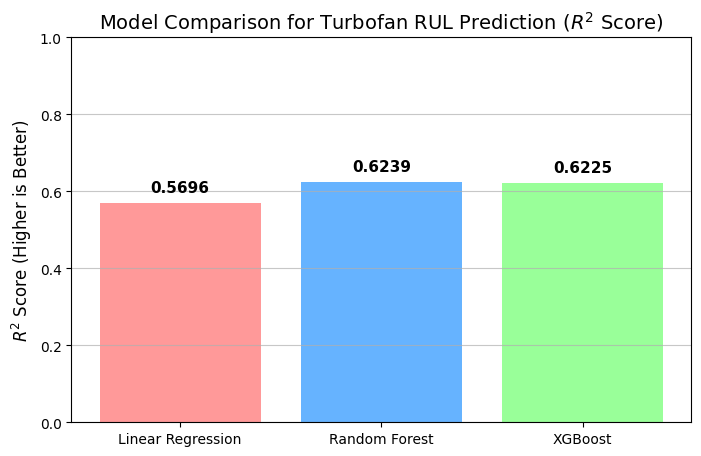

In [77]:
import matplotlib.pyplot as plt
models = ['Linear Regression', 'Random Forest', 'XGBoost']
r2_scores = [r2_lr, r2, r2_xgb]
plt.figure(figsize=(8, 5))
bars = plt.bar(models, r2_scores, color=['#ff9999', '#66b3ff', '#99ff99'])

plt.title(
    'Model Comparison for Turbofan RUL Prediction ($R^2$ Score)', fontsize=14
)
plt.ylabel('$R^2$ Score (Higher is Better)', fontsize=12)
plt.ylim(0, 1.0)

for bar in bars:
  yval = bar.get_height()
  plt.text(
      bar.get_x() + bar.get_width() / 2.0,
      yval + 0.02,
      f'{yval:.4f}',
      ha='center',
      va='bottom',
      fontsize=11,
      fontweight='bold',
  )

plt.grid(axis='y', alpha=0.7)

plt.show()

In [78]:
import joblib

joblib.dump(rf_model, 'turbofan_model.pkl')
joblib.dump(list(X.columns), 'feature_cols.pkl')
print('Model and features saved successfully!')

Model and features saved successfully!
